# Analytické riešenie pružnej zrážky v 2D pomocou SymPy

In [1]:
import numpy as np
import sympy as sp
from sympy.vector import CoordSys3D
N = CoordSys3D('N')
sp.init_printing()

Definujeme premenné, $\mathbf{v_{1,2}}$ a $\mathbf{u_{1,2}}$ sú rýchlosti telies 1 a 2 pred a po zrážke, $x_1, y_1, x_2, y_2$ sú polohy hmotný stredov v okamihu zrážky a $m_{1,2}$ sú hmotnosti.

In [2]:
v1x, v1y, v2x, v2y = sp.symbols('v_{1x} v_{1y} v_{2x} v_{2y}')
u1x, u1y, u2x, u2y = sp.symbols("u_{1x} u_{1y} u_{2x} u_{2y}")
x1, y1, x2, y2 = sp.symbols('x_1 y_1 x_2 y_2')
m1, m2 = sp.symbols('m_1 m_2')

# definujeme vektory rychlosti, polohy a hybnosti pomocou
# suradnicového systému N
v1 = v1x*N.i + v1y*N.j
v2 = v2x*N.i + v2y*N.j
u1 = u1x*N.i + u1y*N.j
u2 = u2x*N.i + u2y*N.j
r1 = x1*N.i + y1*N.j
r2 = x2*N.i + y2*N.j

# hybnosti pred a po zrážke
p1 = m1*v1
p2 = m2*v2
g1 = m1*u1
g2 = m2*u2

Napíšeme zákony zachovania hybnosti, momentu hybnosti a energie.

SymPy rieši rovnice v tvare výraz = 0, preto príslušné veličiny po zrážke presúvame na ľavú stranu so znamienkom -

In [3]:
# zakon zachovani hybnosti v smere x a y
ZZH = p1 + p2 - g1 - g2

# zakon zachovani momentu hybnosti
ZZB = r1.cross(p1) + r2.cross(p2) - r1.cross(g1) - r2.cross(g2)

# zakon zachovani energie
ZZE = p1.dot(p1)/m1 + p2.dot(p2)/m2 - g1.dot(g1)/m1 - g2.dot(g2)/m2

Sprojektujeme vektorové rovnice do príslušných smerov a riešime pre neznáme $\mathbf{u_1}$ a $\mathbf{u_2}$

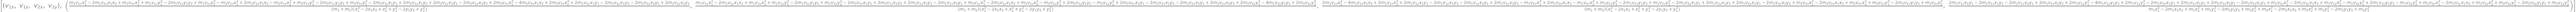

In [4]:
sol = sp.solve([ZZH.dot(N.i), ZZH.dot(N.j), ZZB.dot(N.k), ZZE], [u1x, u1y, u2x, u2y])
sol

1. riešenie je, že telesá spolu intergaovať nebudú (to nás nezaujíma). Druhé riešenie je rozptyl

In [5]:
u1_sol = sol[1][0].simplify()*N.i + sol[1][1].simplify()*N.j
u2_sol = sol[1][2].simplify()*N.i + sol[1][3].simplify()*N.j

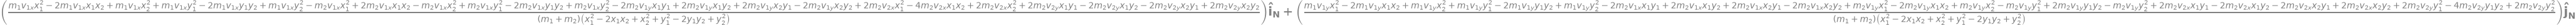

In [6]:
u1_sol.simplify()

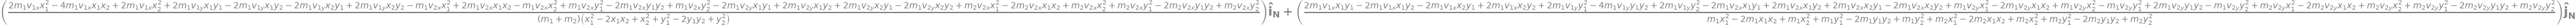

In [7]:
u2_sol.simplify()

Zjednodušme si situáciu predpokladom, že teleso 2 je na počiatku nehybné a v počiatku

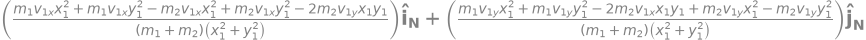

In [8]:
substituce = [(v2x, 0), (v2y, 0), (x2, 0), (y2, 0)]
u1_sol.subs(substituce).simplify()

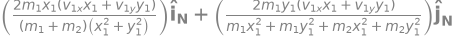

In [9]:
u2_sol.subs(substituce).simplify()

## 1D

In [10]:
p1x, p2x = sp.symbols('p_{1x} p_{2x}')
g1x, g2x = sp.symbols('g_{1x} g_{2x}')

ZZHx = p1x + p2x - g1x - g2x
# 1/2 vykratime
ZZE = p1x**2/m1 + p2x**2/m2 - g1x**2/m1 - g2x**2/m2

sol = sp.solve([ZZHx, ZZE], [g1x, g2x])

In [11]:
sol[0]

In [12]:
sol[1][0].simplify(), sol[1][1].simplify()

In [13]:
sol[1][0] + sol[1][1]

In [14]:
(sol[1][0]**2/m1 + sol[1][1]**2/m2).simplify()

In [15]:
eq = (1/m1 + 1/m2)*g1x**2 - 2/m2*(p1x + p2x)*g1x - (1/m1 - 1/m2)*p1x**2
eq

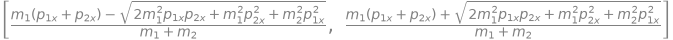

In [16]:
sp.solve(eq, g1x)

In [17]:
ZZE.subs(g2x, p1x + p2x - g1x).simplify().expand().collect(g1x)